In [ ]:
from google.colab import files
uploaded=files.upload()

Saving skin_dataset_10000_plus_original_preserved.csv to skin_dataset_10000_plus_original_preserved (1).csv


In [ ]:
import pandas as pd
df=pd.read_csv('skin_dataset_10000_plus_original_preserved.csv')

In [ ]:
df.head()

,text,skin_type,oiliness,dryness,sensitivity
0,"Most days, I have oily areas around my forehead and nose but drier cheeks.",Combination,High,Medium,Medium
1,I need a lightweight product for my oily T-zone but more moisture on my cheeks. Especially during the day.,Combination,High,Medium,Medium
2,"Recently, My skin usually lacks moisture and can feel rough to the touch.",Dry,Low,Medium,Low
3,"In general, I feel like my skin gets oily even without applying many products. This is fairly consistent for me.",Oily,High,Medium,Low
4,"In general, My cheeks sometimes feel tight even though my T-zone becomes greasy.",Combination,Medium,Medium,Low


In [ ]:
df["text"].value_counts()

,count
text,
"Recently, My face becomes dry easily when I spend time in air conditioning.",15
"I find that After washing my face, it feels stretched and dry for a while.",11
"In general, My skin produces a lot of oil during the day, especially around my nose.",11
I find that I rarely notice shine on my face and sometimes have dry patches.,11
I find that I have oily areas around my forehead and nose but drier cheeks.,11
...,...
"Quite often, greasy patches are not really an issue for me. I hardly ever notice rough patches around my nose or mouth. I rarely notice redness after washing my face. It can be different in the morning compared with the evening.",1
"Over the last few weeks, my face gets shiny soon after my morning routine. My skin feels tight sometimes but not every day. My skin reacts occasionally but usually calms down quickly. It varies a little, but the overall pattern is pretty consistent.",1
"Honestly, my nose and forehead are shiny for much of the day, and my skin feels dry if I forget moisturizer. My face is not easily bothered by most ingredients. It is more noticeable in the afternoon.",1


In [ ]:
text_counts = df["text"].value_counts()

df = df[df["text"].map(text_counts) <= 1].reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Maximum text frequency:", df["text"].value_counts().max())

Dataset shape: (6126, 5)
Maximum text frequency: 1


In [ ]:
df.drop_duplicates()

,text,skin_type,oiliness,dryness,sensitivity
0,I need a lightweight product for my oily T-zone but more moisture on my cheeks. Especially during the day.,Combination,High,Medium,Medium
1,"In general, I feel like my skin gets oily even without applying many products. This is fairly consistent for me.",Oily,High,Medium,Low
2,"Recently, My skin generally feels smooth and balanced. This is fairly consistent for me.",Normal,Medium,Low,Medium
3,My face becomes dry easily when I spend time in air conditioning. Especially during the day.,Dry,Low,High,Medium
4,"In general, My cheeks sometimes feel tight even though my T-zone becomes greasy. It has been like this for a while.",Combination,High,Medium,Low
...,...,...,...,...,...
6121,"Quite often, I rarely have that slippery feeling on my skin, while the skin around my mouth can feel dry in winter. I also find that I rarely feel itchy after using face wash. It doesn't seem to happen only after using one particular product.",Dry,Low,Medium,Low
6122,"For some reason, I notice some oil around my nose later in the day, and the tight feeling often returns after moisturizing. My skin gets red and itchy very easily. It can be different in the morning compared with the evening.",Combination,Medium,High,High
6123,"As far as I can tell, my skin gets greasy even when I use lightweight products. My face does not sting when I apply moisturizer. My cheeks feel rough and flaky on most days.",Combination,High,High,Low
6124,"More often than not, I almost never reach for blotting paper. When it comes to dryness, my face feels dry in places but comfortable elsewhere. As for reactions, some products make my face tingle a little. It is more obvious when the weather is hot or dry.",Dry,Low,Medium,Medium


In [ ]:
df.shape

(6126, 5)

In [ ]:
x=df['text']
y=df["skin_type"]

In [ ]:
!pip install pyspellchecker

In [ ]:
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import re
import spacy

from spellchecker import SpellChecker
from spacy.lang.en.stop_words import STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

nlp = spacy.load("en_core_web_sm")

# Preserve these words during stopword removal and spelling correction
KEEP_WORDS = {
    "not", "no", "never", "neither", "nor", "without",
    "very", "extremely", "highly", "slightly", "quite",
    "too", "really", "barely", "almost", "often", "usually",
    "sometimes", "rarely", "always", "frequently", "occasionally",
    "more", "less", "most", "least", "much", "little",
    "high", "medium", "low",
    "oily", "dry", "sensitive", "normal", "combination",
    "skin", "face", "forehead", "cheeks", "pores", "acne",
    "greasy", "itchy", "irritated", "tight", "flaky",
    "hydrated", "dehydrated", "redness", "breakouts"
}

# Explicit, skin-context typo corrections
CUSTOM_CORRECTIONS = {
    "skinn": "skin",
    "sking": "skin",
    "skine": "skin",
    "oiley": "oily",
    "oilness": "oiliness",
    "sensetive": "sensitive",
    "sensetivity": "sensitivity",
    "drynes": "dryness",
    "moisturiser": "moisturizer",
    "moisturiser's": "moisturizer"
}

spell = SpellChecker()
spell.word_frequency.load_words(KEEP_WORDS)
spell.word_frequency.load_words(CUSTOM_CORRECTIONS.values())

CONTRACTIONS = {
    "can't": "cannot",
    "won't": "will not",
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "it's": "it is",
    "i'm": "i am",
    "i've": "i have",
    "i'll": "i will",
    "you're": "you are",
    "they're": "they are",
    "that's": "that is"
}

# 1. Basic preprocessing
def basic_preprocessing(texts):
    results = []

    for text in texts:
        text = str(text).lower().strip()

        for contraction, expanded in CONTRACTIONS.items():
            text = re.sub(
                r"\b" + re.escape(contraction) + r"\b",
                expanded, text
            )

        text = re.sub(r"[^a-z\s]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        results.append(text)

    return results


# 2. Conservative spelling correction
def spelling_correction(texts):
    results = []

    for text in texts:
        corrected_words = []

        for word in text.split():
            if word in CUSTOM_CORRECTIONS:
                corrected_words.append(CUSTOM_CORRECTIONS[word])

            elif word in KEEP_WORDS or len(word) <= 2:
                corrected_words.append(word)

            else:
                # Only accept a correction for a one-character typo.
                candidate = spell.correction(word)

                if (
                    candidate
                    and candidate != word
                    and spell.unknown([word])
                    and len(word) >= 4
                    and spell.known([candidate])
                    and abs(len(candidate) - len(word)) <= 1
                ):
                    corrected_words.append(candidate)
                else:
                    corrected_words.append(word)

        results.append(" ".join(corrected_words))

    return results


# 3. Stopword removal while preserving intensifiers and negations
def stopword_removal(texts):
    results = []

    for text in texts:
        words = [
            word for word in text.split()
            if word not in STOP_WORDS or word in KEEP_WORDS
        ]
        results.append(" ".join(words))

    return results


# 4. Lemmatization
# 4. POS-tag-aware lemmatization
def lemmatization(texts):
    results = []

    for doc in nlp.pipe(texts, batch_size=64):
        lemmas = []

        for token in doc:
            if token.is_space or token.is_punct:
                continue

            # Use spaCy's POS-aware lemma
            lemma = token.lemma_.lower()

            lemmas.append(lemma)

        results.append(" ".join(lemmas))

    return results


print("All four preprocessing functions are ready.")

All four preprocessing functions are ready.


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split(
    x, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))


Training samples: 4900
Validation samples: 613
Test samples: 613


In [ ]:
preprocessing_pipeline = Pipeline([
    ("basic_preprocessing",
     FunctionTransformer(basic_preprocessing, validate=False)),

    ("spelling_correction",
     FunctionTransformer(spelling_correction, validate=False)),

    ("stopword_removal",
     FunctionTransformer(stopword_removal, validate=False)),

    ("lemmatization",
     FunctionTransformer(lemmatization, validate=False))
])

print(preprocessing_pipeline)

Pipeline(steps=[('basic_preprocessing',
                 FunctionTransformer(func=<function basic_preprocessing at 0x7dc4f77372e0>)),
                ('spelling_correction',
                 FunctionTransformer(func=<function spelling_correction at 0x7dc4f7737880>)),
                ('stopword_removal',
                 FunctionTransformer(func=<function stopword_removal at 0x7dc4f77377e0>)),
                ('lemmatization',
                 FunctionTransformer(func=<function lemmatization at 0x7dc4f7737ec0>))])


In [ ]:
def process_with_steps(text):
    current = [text]

    print("Original:", current[0])

    steps = [
        ("Basic preprocessing", basic_preprocessing),
        ("Spelling correction", spelling_correction),
        ("Stopword removal", stopword_removal),
        ("Lemmatization", lemmatization)
    ]

    for step_name, function in steps:
        current = function(current)
        print(f"\n{step_name}:\n{current[0]}")

    return current[0]


sample_text = "My slin has extreme oilyness and never dry"
processed_text = process_with_steps(sample_text)

Original: My slin has extreme oilyness and never dry

Basic preprocessing:
my slin has extreme oilyness and never dry

Spelling correction:
my skin has extreme oiliness and never dry

Stopword removal:
skin extreme oiliness never dry

Lemmatization:
skin extreme oiliness never dry


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.base import clone

# Pipeline 1: TF-IDF + Logistic Regression
lr_pipeline = Pipeline([
    ("preprocessing", clone(preprocessing_pipeline)),
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=10000,
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Pipeline 2: TF-IDF + Linear SVM
svm_pipeline = Pipeline([
    ("preprocessing", clone(preprocessing_pipeline)),
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=10000,
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

# Train both models using the same training split
print("Training Logistic Regression...")
lr_pipeline.fit(X_train, y_train)

print("Training SVM...")
svm_pipeline.fit(X_train, y_train)

print("Both models trained successfully!")

Training Logistic Regression...
Training SVM...
Both models trained successfully!


In [ ]:
import pandas as pd
import numpy as np

print("=== DATASET CHECK ===")
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

print("\n=== SKIN TYPE DISTRIBUTION ===")
print("Train:\n", y_train.value_counts())
print("\nValidation:\n", y_val.value_counts())
print("\nTest:\n", y_test.value_counts())

# Exact raw-text overlap between splits
train_texts = set(X_train.astype(str).str.strip().str.lower())
val_texts = set(X_val.astype(str).str.strip().str.lower())
test_texts = set(X_test.astype(str).str.strip().str.lower())

print("\n=== EXACT TEXT OVERLAP ===")
print("Train ∩ Validation:", len(train_texts & val_texts))
print("Train ∩ Test:", len(train_texts & test_texts))
print("Validation ∩ Test:", len(val_texts & test_texts))

# Does the same exact text have different labels?
label_counts = df.groupby("text")["skin_type"].nunique()
conflicts = label_counts[label_counts > 1]

print("\n=== CONFLICTING LABELS ===")
print("Texts assigned multiple skin types:", len(conflicts))

# Duplicate rows and repeated descriptions
print("\n=== DUPLICATES ===")
print("Exact duplicate text rows:", df["text"].duplicated().sum())
print("Most frequent descriptions:")
print(df["text"].value_counts().head(10))

=== DATASET CHECK ===
Training rows: 4900
Validation rows: 613
Test rows: 613

=== SKIN TYPE DISTRIBUTION ===
Train:
 skin_type
Combination    2053
Normal         1128
Dry            1074
Oily            645
Name: count, dtype: int64

Validation:
 skin_type
Combination    257
Normal         141
Dry            134
Oily            81
Name: count, dtype: int64

Test:
 skin_type
Combination    257
Normal         141
Dry            135
Oily            80
Name: count, dtype: int64

=== EXACT TEXT OVERLAP ===
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

=== CONFLICTING LABELS ===
Texts assigned multiple skin types: 0

=== DUPLICATES ===
Exact duplicate text rows: 0
Most frequent descriptions:
text
For some reason, I almost never reach for blotting paper. I get itchy patches after using lots of different creams. My skin feels fine in both warm and cool weather.    1
I need a lightweight product for my oily T-zone but more moisture on my cheeks. Especially during the day.        

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": lr_pipeline,
    "Linear SVM": svm_pipeline
}

validation_predictions = {}
test_predictions = {}
metrics = []

for name, model in models.items():
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    validation_predictions[name] = val_pred
    test_predictions[name] = test_pred

    metrics.append({
        "Model": name,
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Validation Macro F1": f1_score(
            y_val, val_pred, average="macro", zero_division=0
        ),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Test Macro F1": f1_score(
            y_test, test_pred, average="macro", zero_division=0
        ),
        "Test Weighted F1": f1_score(
            y_test, test_pred, average="weighted", zero_division=0
        )
    })

metrics_df = pd.DataFrame(metrics)
display(metrics_df.round(4))

,Model,Validation Accuracy,Validation Macro F1,Test Accuracy,Test Macro F1,Test Weighted F1
0,Logistic Regression,0.9951,0.9927,0.9984,0.9976,0.9984
1,Linear SVM,1.0000,1.0000,1.0000,1.0000,1.0000


In [ ]:
comparison = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "Actual": y_test.reset_index(drop=True),
    "LR Prediction": test_predictions["Logistic Regression"],
    "SVM Prediction": test_predictions["Linear SVM"]
})

comparison["LR Correct"] = (
    comparison["Actual"] == comparison["LR Prediction"]
)
comparison["SVM Correct"] = (
    comparison["Actual"] == comparison["SVM Prediction"]
)

# Show disagreements first
disagreements = comparison[
    comparison["LR Prediction"] != comparison["SVM Prediction"]
]

print("Number of test examples where models disagree:", len(disagreements))
display(disagreements.head(30))

print("\nLogistic Regression mistakes:")
display(comparison[~comparison["LR Correct"]].head(20))

print("\nSVM mistakes:")
display(comparison[~comparison["SVM Correct"]].head(20))

Number of test examples where models disagree: 1


,text,Actual,LR Prediction,SVM Prediction,LR Correct,SVM Correct
391,"For some reason, my forehead can look shiny after a few hours. When it comes to dryness, I do not need to reapply moisturizer to feel comfortable. As for reactions, I occasionally feel a short sting when applying skincare. It usually shows up during my normal routine.",Normal,Oily,Normal,False,True



Logistic Regression mistakes:


,text,Actual,LR Prediction,SVM Prediction,LR Correct,SVM Correct
391,"For some reason, my forehead can look shiny after a few hours. When it comes to dryness, I do not need to reapply moisturizer to feel comfortable. As for reactions, I occasionally feel a short sting when applying skincare. It usually shows up during my normal routine.",Normal,Oily,Normal,False,True



SVM mistakes:


,text,Actual,LR Prediction,SVM Prediction,LR Correct,SVM Correct



==================== Logistic Regression ====================
              precision    recall  f1-score   support

 Combination       1.00      1.00      1.00       257
         Dry       1.00      1.00      1.00       135
      Normal       1.00      0.99      1.00       141
        Oily       0.99      1.00      0.99        80

    accuracy                           1.00       613
   macro avg       1.00      1.00      1.00       613
weighted avg       1.00      1.00      1.00       613



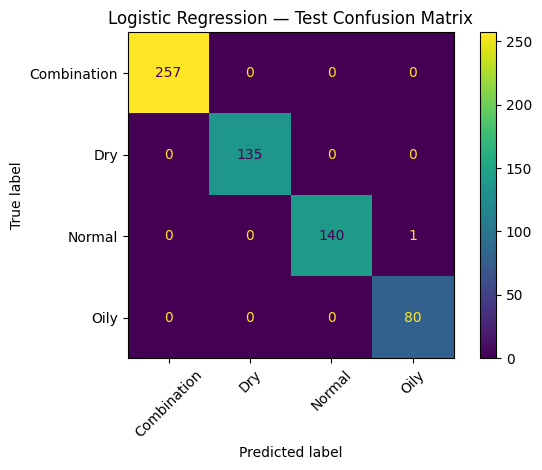


==================== Linear SVM ====================
              precision    recall  f1-score   support

 Combination       1.00      1.00      1.00       257
         Dry       1.00      1.00      1.00       135
      Normal       1.00      1.00      1.00       141
        Oily       1.00      1.00      1.00        80

    accuracy                           1.00       613
   macro avg       1.00      1.00      1.00       613
weighted avg       1.00      1.00      1.00       613



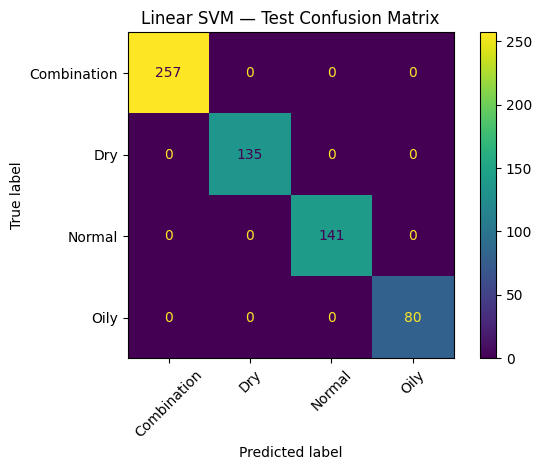

In [ ]:
for name, model in models.items():
    print(f"\n{'=' * 20} {name} {'=' * 20}")

    pred = test_predictions[name]

    print(classification_report(
        y_test,
        pred,
        labels=model.classes_,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        labels=model.classes_,
        xticks_rotation=45,
        values_format="d"
    )
    plt.title(f"{name} — Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [ ]:

# Check class distribution
print("Skin-type distribution:")
print(df["skin_type"].value_counts())

print("\nNumber of unique texts:", df["text"].nunique())
print("Number of rows:", len(df))

# Look for skin-type labels explicitly mentioned in the text
label_words = ["normal", "dry", "oily", "combination"]

for label in label_words:
    matching = df["text"].astype(str).str.contains(
        rf"\b{label}\b", case=False, regex=True, na=False
    )
    print(f"Texts containing '{label}': {matching.sum()}")


Skin-type distribution:
skin_type
Combination    2567
Normal         1410
Dry            1343
Oily            806
Name: count, dtype: int64

Number of unique texts: 6126
Number of rows: 6126
Texts containing 'normal': 242
Texts containing 'dry': 1681
Texts containing 'oily': 1052
Texts containing 'combination': 0


In [ ]:

test_texts = [
    "My skinn feels very dry and tight after washing my face.",
    "My face is not oily, but my cheeks are dry and flaky.",
    "I have an oiley forehead, large pores, and dry cheeks.",
    "My skin is extremely sensitive and sometimes gets red and itchy.",
    "My skin feels normal most days, but gets a little greasy around my nose.",
    "Quite often, I rarely have that slippery feeling on my skin, while the skin around my mouth can feel dry in winter. I also find that I rarely feel itchy after using face wash. It doesn't seem to happen only after using one particular product. "
]


In [ ]:

def show_preprocessing_stages(text):
    stage1 = basic_preprocessing([text])[0]
    stage2 = spelling_correction([stage1])[0]
    stage3 = stopword_removal([stage2])[0]
    stage4 = lemmatization([stage3])[0]

    return {
        "Original Text": text,
        "1. Basic Preprocessing": stage1,
        "2. Spelling Correction": stage2,
        "3. Stopword Removal": stage3,
        "4. Lemmatization (Final)": stage4
    }

preprocessing_results = pd.DataFrame(
    [show_preprocessing_stages(text) for text in test_texts]
)

pd.set_option("display.max_colwidth", None)
display(preprocessing_results.T)


,0,1,2,3,4,5
Original Text,My skinn feels very dry and tight after washing my face.,"My face is not oily, but my cheeks are dry and flaky.","I have an oiley forehead, large pores, and dry cheeks.",My skin is extremely sensitive and sometimes gets red and itchy.,"My skin feels normal most days, but gets a little greasy around my nose.","Quite often, I rarely have that slippery feeling on my skin, while the skin around my mouth can feel dry in winter. I also find that I rarely feel itchy after using face wash. It doesn't seem to happen only after using one particular product."
1. Basic Preprocessing,my skinn feels very dry and tight after washing my face,my face is not oily but my cheeks are dry and flaky,i have an oiley forehead large pores and dry cheeks,my skin is extremely sensitive and sometimes gets red and itchy,my skin feels normal most days but gets a little greasy around my nose,quite often i rarely have that slippery feeling on my skin while the skin around my mouth can feel dry in winter i also find that i rarely feel itchy after using face wash it does not seem to happen only after using one particular product
2. Spelling Correction,my skin feels very dry and tight after washing my face,my face is not oily but my cheeks are dry and flaky,i have an oily forehead large pores and dry cheeks,my skin is extremely sensitive and sometimes gets red and itchy,my skin feels normal most days but gets a little greasy around my nose,quite often i rarely have that slippery feeling on my skin while the skin around my mouth can feel dry in winter i also find that i rarely feel itchy after using face wash it does not seem to happen only after using one particular product
3. Stopword Removal,skin feels very dry tight washing face,face not oily cheeks dry flaky,oily forehead large pores dry cheeks,skin extremely sensitive sometimes gets red itchy,skin feels normal most days gets little greasy nose,quite often rarely slippery feeling skin skin mouth feel dry winter find rarely feel itchy face wash not happen particular product
4. Lemmatization (Final),skin feel very dry tight washing face,face not oily cheek dry flaky,oily forehead large pore dry cheek,skin extremely sensitive sometimes get red itchy,skin feel normal most day get little greasy nose,quite often rarely slippery feel skin skin mouth feel dry winter find rarely feel itchy face wash not happen particular product


In [ ]:

import numpy as np
import pandas as pd

def get_prediction_details(model, text):
    predicted_label = model.predict([text])[0]
    classifier = model.named_steps["classifier"]

    details = {
        "Predicted Skin Type": predicted_label
    }

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba([text])[0]
        classes = model.named_steps["classifier"].classes_

        details["Confidence Type"] = "Predicted-class probability"
        details["Confidence (%)"] = round(
            float(np.max(probabilities)) * 100, 2
        )
        details["Class Scores (%)"] = {
            str(label): round(float(prob) * 100, 2)
            for label, prob in zip(classes, probabilities)
        }

    elif hasattr(model, "decision_function"):
        scores = model.decision_function([text])
        classes = model.named_steps["classifier"].classes_

        if scores.ndim == 1 and len(classes) == 2:
            # Binary SVM: decision score is signed toward classes_[1].
            class_scores = {
                str(classes[0]): float(-scores[0]),
                str(classes[1]): float(scores[0])
            }
        else:
            class_scores = {
                str(label): float(score)
                for label, score in zip(classes, scores[0])
            }

        # Relative score only; not a probability.
        score_values = np.array(list(class_scores.values()))
        shifted = score_values - np.max(score_values)
        relative_scores = np.exp(shifted) / np.exp(shifted).sum()

        details["Confidence Type"] = "SVM relative score (not probability)"
        details["Confidence (%)"] = round(
            float(np.max(relative_scores)) * 100, 2
        )
        details["Class Scores (%)"] = {
            label: round(float(score) * 100, 2)
            for label, score in zip(class_scores.keys(), relative_scores)
        }

    return details


rows = []

for i, text in enumerate(test_texts, start=1):
    processed = preprocessing_pipeline.transform([text])[0]

    for model_name, model in [
        ("SVM", svm_pipeline),
        ("Logistic Regression", lr_pipeline)
    ]:
        result = get_prediction_details(model, text)

        rows.append({
            "Sample": i,
            "Model": model_name,
            "Original Text": text,
            "Final Preprocessed Text": processed,
            **result
        })

prediction_results = pd.DataFrame(rows)

display(prediction_results[
    [
        "Sample",
        "Model",
        "Original Text",
        "Final Preprocessed Text",
        "Predicted Skin Type",
        "Confidence Type",
        "Confidence (%)",
        "Class Scores (%)"
    ]
])


,Sample,Model,Original Text,Final Preprocessed Text,Predicted Skin Type,Confidence Type,Confidence (%),Class Scores (%)
0,1,SVM,My skinn feels very dry and tight after washing my face.,skin feel very dry tight washing face,Dry,SVM relative score (not probability),79.24,"{'Combination': 16.24, 'Dry': 79.24, 'Normal': 2.68, 'Oily': 1.83}"
1,1,Logistic Regression,My skinn feels very dry and tight after washing my face.,skin feel very dry tight washing face,Dry,Predicted-class probability,79.12,"{'Combination': 18.23, 'Dry': 79.12, 'Normal': 1.39, 'Oily': 1.27}"
2,2,SVM,"My face is not oily, but my cheeks are dry and flaky.",face not oily cheek dry flaky,Normal,SVM relative score (not probability),37.56,"{'Combination': 32.86, 'Dry': 23.12, 'Normal': 37.56, 'Oily': 6.46}"
3,2,Logistic Regression,"My face is not oily, but my cheeks are dry and flaky.",face not oily cheek dry flaky,Combination,Predicted-class probability,36.77,"{'Combination': 36.77, 'Dry': 24.04, 'Normal': 36.24, 'Oily': 2.94}"
4,3,SVM,"I have an oiley forehead, large pores, and dry cheeks.",oily forehead large pore dry cheek,Combination,SVM relative score (not probability),62.20,"{'Combination': 62.2, 'Dry': 16.06, 'Normal': 12.51, 'Oily': 9.23}"
5,3,Logistic Regression,"I have an oiley forehead, large pores, and dry cheeks.",oily forehead large pore dry cheek,Combination,Predicted-class probability,71.93,"{'Combination': 71.93, 'Dry': 15.86, 'Normal': 5.47, 'Oily': 6.74}"
6,4,SVM,My skin is extremely sensitive and sometimes gets red and itchy.,skin extremely sensitive sometimes get red itchy,Combination,SVM relative score (not probability),41.85,"{'Combination': 41.85, 'Dry': 25.66, 'Normal': 22.28, 'Oily': 10.21}"
7,4,Logistic Regression,My skin is extremely sensitive and sometimes gets red and itchy.,skin extremely sensitive sometimes get red itchy,Combination,Predicted-class probability,38.99,"{'Combination': 38.99, 'Dry': 31.84, 'Normal': 19.61, 'Oily': 9.56}"
8,5,SVM,"My skin feels normal most days, but gets a little greasy around my nose.",skin feel normal most day get little greasy nose,Combination,SVM relative score (not probability),80.34,"{'Combination': 80.34, 'Dry': 5.9, 'Normal': 11.58, 'Oily': 2.18}"
9,5,Logistic Regression,"My skin feels normal most days, but gets a little greasy around my nose.",skin feel normal most day get little greasy nose,Combination,Predicted-class probability,84.87,"{'Combination': 84.87, 'Dry': 5.43, 'Normal': 7.95, 'Oily': 1.76}"


In [ ]:

import pandas as pd
from sklearn.metrics import accuracy_score

# A. Compare performance across all splits
for name, model in [
    ("SVM", svm_pipeline),
    ("Logistic Regression", lr_pipeline)
]:
    print(f"\n{'='*45}\n{name}")

    for split, X_part, y_part in [
        ("Train", X_train, y_train),
        ("Validation", X_val, y_val),
        ("Test", X_test, y_test)
    ]:
        pred = model.predict(X_part)
        print(
            f"{split:10s} n={len(X_part):4d} | "
            f"accuracy={accuracy_score(y_part, pred):.4f}"
        )

# B. Check for exact raw-text overlap across splits
def normalize_for_check(series):
    return series.astype(str).str.lower().str.strip()

train_texts = set(normalize_for_check(X_train))
val_texts = set(normalize_for_check(X_val))
test_texts = set(normalize_for_check(X_test))

print("\nExact text overlap:")
print("Train ∩ Validation:", len(train_texts & val_texts))
print("Train ∩ Test:", len(train_texts & test_texts))
print("Validation ∩ Test:", len(val_texts & test_texts))

# C. Check for contradictory labels within the full cleaned dataset
label_counts = (
    pd.DataFrame({
        "text": normalize_for_check(df["text"]),
        "label": df["skin_type"].astype(str).str.strip()
    })
    .groupby("text")["label"]
    .nunique()
)

print("\nUnique texts with multiple labels:", (label_counts > 1).sum())



SVM
Train      n=4900 | accuracy=1.0000
Validation n= 613 | accuracy=1.0000
Test       n= 613 | accuracy=1.0000

Logistic Regression
Train      n=4900 | accuracy=0.9996
Validation n= 613 | accuracy=0.9951
Test       n= 613 | accuracy=0.9984

Exact text overlap:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

Unique texts with multiple labels: 0


In [ ]:

import pandas as pd
import re

# Look for explicit skin-type words in the text
for label in ["normal", "dry", "oily", "combination"]:
    mask = df["text"].astype(str).str.contains(
        rf"\b{label}\b", case=False, regex=True, na=False
    )

    print(f"\nText contains '{label}': {mask.sum()} rows")

    if mask.any():
        print(
            df.loc[mask, ["text", "skin_type"]]
              .head(5)
              .to_string(index=False)
        )



Text contains 'normal': 242 rows
                                                                                                                    text   skin_type
              Recently, My nose and forehead become shiny while my cheeks feel normal or dry. Especially during the day. Combination
Most days, My nose and forehead become shiny while my cheeks feel normal or dry. I notice this more in changing weather. Combination
                 My nose and forehead become shiny while my cheeks feel normal or dry. This is fairly consistent for me. Combination
             In general, My nose and forehead become shiny while my cheeks feel normal or dry. This happens quite often. Combination
   Usually, My nose and forehead become shiny while my cheeks feel normal or dry. It is more noticeable after cleansing. Combination

Text contains 'dry': 1681 rows
                                                                                                                 text   skin_type
      

In [ ]:

import pandas as pd
import re

# Look for explicit skin-type words in the text
for label in ["normal", "dry", "oily", "combination"]:
    mask = df["text"].astype(str).str.contains(
        rf"\b{label}\b", case=False, regex=True, na=False
    )

    print(f"\nText contains '{label}': {mask.sum()} rows")

    if mask.any():
        print(
            df.loc[mask, ["text", "skin_type"]]
              .head(5)
              .to_string(index=False)
        )



Text contains 'normal': 242 rows
                                                                                                                    text   skin_type
              Recently, My nose and forehead become shiny while my cheeks feel normal or dry. Especially during the day. Combination
Most days, My nose and forehead become shiny while my cheeks feel normal or dry. I notice this more in changing weather. Combination
                 My nose and forehead become shiny while my cheeks feel normal or dry. This is fairly consistent for me. Combination
             In general, My nose and forehead become shiny while my cheeks feel normal or dry. This happens quite often. Combination
   Usually, My nose and forehead become shiny while my cheeks feel normal or dry. It is more noticeable after cleansing. Combination

Text contains 'dry': 1681 rows
                                                                                                                 text   skin_type
      

In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

train_text = preprocessing_pipeline.transform(list(X_train))
test_text = preprocessing_pipeline.transform(list(X_test))

vec = TfidfVectorizer(ngram_range=(1, 2))
train_matrix = vec.fit_transform(train_text)
test_matrix = vec.transform(test_text)

# For each test row, find its most similar training row
similarity = cosine_similarity(test_matrix, train_matrix)
nearest = similarity.max(axis=1)

print("Highest train-test similarity:", round(nearest.max(), 4))
print("Median nearest similarity:", round(np.median(nearest), 4))
print("Test rows with similarity >= 0.90:", (nearest >= 0.90).sum())
print("Test rows with similarity >= 0.95:", (nearest >= 0.95).sum())

top_idx = np.argsort(nearest)[::-1][:10]

display(pd.DataFrame({
    "Test Text": X_test.iloc[top_idx].values,
    "True Label": y_test.iloc[top_idx].values,
    "Nearest Train Text": X_train.iloc[similarity.argmax(axis=1)[top_idx]].values,
    "Nearest Train Label": y_train.iloc[similarity.argmax(axis=1)[top_idx]].values,
    "Similarity": np.round(nearest[top_idx], 4)
}))


Highest train-test similarity: 1.0
Median nearest similarity: 0.5218
Test rows with similarity >= 0.90: 60
Test rows with similarity >= 0.95: 20


,Test Text,True Label,Nearest Train Text,Nearest Train Label,Similarity
0,"For me, The center of my face gets oily but the outer areas often need more moisture. Especially during the day.",Combination,The center of my face gets oily but the outer areas often need more moisture. Especially during the day.,Combination,1.0000
1,"After washing my face, it feels stretched and dry for a while. It has been like this for a while.",Dry,"For me, After washing my face, it feels stretched and dry for a while. It has been like this for a while.",Dry,1.0000
2,"For me, I need a lightweight product for my oily T-zone but more moisture on my cheeks. Especially during the day.",Combination,I need a lightweight product for my oily T-zone but more moisture on my cheeks. Especially during the day.,Combination,1.0000
3,"For me, My skin generally needs only a moderate amount of moisturizer. This happens quite often.",Normal,My skin generally needs only a moderate amount of moisturizer. This happens quite often.,Normal,1.0000
4,Most skincare products do not make my skin unusually oily or dry. It is more noticeable after cleansing.,Normal,"For me, Most skincare products do not make my skin unusually oily or dry. It is more noticeable after cleansing.",Normal,1.0000
5,My nose gets shiny quickly while the sides of my face feel dry. It has been like this for a while.,Combination,"For me, My nose gets shiny quickly while the sides of my face feel dry. It has been like this for a while.",Combination,1.0000
6,"Usually, Heavy moisturizers make my face feel excessively greasy. It is more noticeable after cleansing.",Oily,Heavy moisturizers make my face feel excessively greasy. It is more noticeable after cleansing.,Oily,0.9937
7,"Recently, Moisturizer makes a big difference because my skin gets tight without it. It has been like this for a while.",Dry,Moisturizer makes a big difference because my skin gets tight without it. It has been like this for a while.,Dry,0.9860
8,My skin usually feels balanced and neither very oily nor very dry. It is more noticeable after cleansing.,Normal,I find that My skin usually feels balanced and neither very oily nor very dry. It is more noticeable after cleansing.,Normal,0.9743
9,I've noticed that I often have a greasy feeling on my forehead and cheeks. This is fairly consistent for me.,Oily,I often have a greasy feeling on my forehead and cheeks. This is fairly consistent for me.,Oily,0.9648


In [ ]:

svm_classifier = svm_pipeline.named_steps["classifier"]
tfidf = svm_pipeline.named_steps["tfidf"]

feature_names = tfidf.get_feature_names_out()
classes = svm_classifier.classes_

for i, label in enumerate(classes):
    print(f"\nTop features for {label}:")

    top_indices = np.argsort(svm_classifier.coef_[i])[-15:][::-1]

    print([
        (feature_names[j], round(svm_classifier.coef_[i][j], 3))
        for j in top_indices
    ])



Top features for Combination:
[('area', np.float64(2.087)), ('get', np.float64(1.902)), ('skin feel', np.float64(1.843)), ('bit', np.float64(1.691)), ('place', np.float64(1.607)), ('chin', np.float64(1.592)), ('shiny', np.float64(1.538)), ('often feel', np.float64(1.506)), ('patch peel', np.float64(1.488)), ('cheek feel', np.float64(1.455)), ('forehead get', np.float64(1.443)), ('dry', np.float64(1.403)), ('dry place', np.float64(1.35)), ('zone', np.float64(1.323)), ('zone get', np.float64(1.284))]

Top features for Dry:
[('comfortable oily', np.float64(3.491)), ('usually shiny', np.float64(2.869)), ('rarely look', np.float64(2.722)), ('very little', np.float64(2.415)), ('blot skin', np.float64(2.274)), ('matte', np.float64(2.234)), ('usually need', np.float64(2.136)), ('slick day', np.float64(2.098)), ('not slick', np.float64(2.098)), ('day without', np.float64(2.098)), ('without feel', np.float64(2.098)), ('not greasy', np.float64(1.848)), ('place comfortable', np.float64(1.846)), (

In [ ]:

import pandas as pd

suspicious_features = [
    "comfortable oily",
    "usually shiny",
    "rarely look",
    "not slick",
    "cheek not",
    "not peel"
]

train_processed = preprocessing_pipeline.transform(list(X_train))

for feature in suspicious_features:
    print(f"\n{'=' * 65}")
    print(f"FEATURE: {feature!r}")

    mask = pd.Series(train_processed).str.contains(
        feature, regex=False, case=False
    )

    if mask.any():
        examples = pd.DataFrame({
            "Processed Text": pd.Series(train_processed)[mask].values,
            "Label": y_train.iloc[mask[mask].index].values
        })
        print("Occurrences:", len(examples))
        display(examples.head(10))
    else:
        print("No matching processed training examples found.")



FEATURE: 'comfortable oily'
Occurrences: 58


,Processed Text,Label
0,skin feel comfortable oily hand area feel rough rest face fine skin get irritated different ingredient,Dry
1,thing notice skin feel comfortable oily gentle cleanser often leave face irritated face feel comfortable wash,Normal
2,typical day skin feel comfortable oily face feel soft without need lot cream find skin get itchy use heavily fragrance cream more noticeable afternoon,Normal
3,skin tend skin feel comfortable oily not often flaky skin nose find skin handle routine pretty come go depend day,Normal
4,honestly skin feel comfortable oily skin peel repeatedly week face react product people tolerate base usually experience not day,Dry
5,honestly skin feel comfortable oily skin tolerate sunscreen without trouble cheek little dry weather turn cold,Dry
6,experience skin feel comfortable oily not need reapply moisturizer feel comfortable skin occasionally get itchy try new noticed thing different week,Normal
7,week skin feel comfortable oily sometimes need moisturizer ease tight feeling skin react occasionally usually calm quickly notice thing different week,Dry
8,quite often skin feel comfortable oily apart face feel dry place comfortable face red quickly try new product,Dry
9,notice skin feel comfortable oily area feel rough rest face fine cheek sometimes turn red cold windy weather not happen particular product,Dry



FEATURE: 'usually shiny'
Occurrences: 62


,Processed Text,Label
0,more often not nose not usually shiny sunscreen sting cheek day face feel tight almost time wash,Dry
1,lot time nose not usually shiny skin usually feel balanced comfortable skincare product face burn sting notice more season,Normal
2,lot time nose not usually shiny cheek need extra cream day skin tolerate sunscreen without trouble deal regular basis,Dry
3,generally nose not usually shiny dry patch face hard ignore find skin tolerate sunscreen without trouble notice more busy day hour,Dry
4,honestly nose not usually shiny skin stay comfortable skincare step notice cheek red hot shower,Normal
5,skin tend nose not usually shiny hardly notice rough patch nose mouth often stop product ste not happen particular product,Normal
6,generally nose not usually shiny lately face feel tight almost time wash occasionally feel short sting apply skincare more obvious weather hot dry,Dry
7,nose not usually shiny lately reapply moisturizer skin feels parch itchy patch lot different cream more obvious weather hot dry,Dry
8,everyday life nose not usually shiny dryness noticeable most day not winter face red quickly try new product happens often start pay attention,Dry
9,quite often nose not usually shiny face feel comfortable wash skin react occasionally usually calm quickly notice more washing face,Normal



FEATURE: 'rarely look'
Occurrences: 132


,Processed Text,Label
0,lot time cheek nose rarely look oily cheek feel rough flaky most day face not ste apply moisturizer bad condition,Dry
1,skin tend cheek nose rarely look oily come dryness dryness noticeable most day not winter reaction face red quickly try new product notice most weather change,Dry
2,honest skin rarely look shiny sweating cheek stay soft most day find rarely notice redness washing face deal regular basis,Normal
3,thing notice skin rarely look shiny sweating sometimes need moisturizer ease tight feeling face red quickly try new product come go depend day,Dry
4,skin tend skin rarely look shiny sweat noticeable scale nose mouth most skincare product agree skin annoying learn expect skin,Dry
5,recently cheek nose rarely look oily not often flaky skin nose exfoliate product leave skin feel irritated tend happen routine simple,Normal
6,generally cheek nose rarely look oily lately cheek feel tight end day skin get red itchy very easily different morning compare evening,Dry
7,notice skin rarely look shiny sweating skin generally feel smooth comfortable noticed itchy patch lot different cream,Normal
8,reason cheek nose rarely look oily skin tolerate sunscreen without trouble face feels stretch uncomfortable cleansing,Dry
9,thing notice cheek nose rarely look oily rarely feel irritation cleanse skin get scaly place,Dry


... (2 outputs left out)


FEATURE: 'cheek not'
Occurrences: 144


,Processed Text,Label
0,skin tend forehead nose cheek noticeably greasy dry patch not deal often find face not react easily everyday product not happen particular product,Oily
1,generally touch face oil lately cheek not usually feel rough rarely prickly feel apply cream notice more washing face,Oily
2,reason skin feel slick oily lunchtime cheek not usually feel rough noticed skin usually handle change weather,Oily
3,everyday life face get greasy not long wash cheek not usually feel rough skin react everyday product not tends happen routine simple,Oily
4,experience forehead nose cheek noticeably greasy cheek need extra cream day skin occasionally get itchy try new base usually experience not day,Combination
5,notice forehead nose cheek noticeably greasy cheek feel rough flaky most day skin get itchy use heavily fragrance cream especially noticeable day,Combination
6,forehead nose cheek noticeably greasy occasional flaking settle moisturizer skin often burn apply moisturizer noticing month,Combination
7,quite often forehead nose cheek noticeably greasy cheek not usually feel rough find face rarely get red itchy product not notice single day happen fairly often,Oily
8,generally forehead nose cheek noticeably greasy face feel uncomfortable without regular moisturizer occasionally feel short sting applying skincare come go depend day,Combination
9,week oil appear quickly area face cheek not usually feel rough find skin often burn apply moisturizer especially noticeable day,Oily



FEATURE: 'not peel'
Occurrences: 46


,Processed Text,Label
0,honestly oiliness come go weather change not tend bother skin skin not peel feel uncomfortable,Normal
1,recently face often feel slippery touch skin not peel feel uncomfortable exfoliating product leave skin feel irritated bad condition,Oily
2,everyday life greasy patches not really issue think routine skin not peel feel uncomfortable face sometimes get little red settle,Normal
3,honestly skin usually stay matte never feel greasy skin not peel feel uncomfortable react strongly lot fragrance product pretty regular pattern,Normal
4,week sometimes blot nose not constantly come dryness skin not peel feel uncomfortable reaction often feel burn itching sting skincare especially noticeable day,Normal
5,personally t zone stay fairly matte skin not peel feel uncomfortable noticed face not easily bother most ingredient,Normal
6,quite often greasy patches not really issue skin not peel feel uncomfortable certain moisturizer skin sting briefly start pay attention change routine,Normal
7,notice forehead look shiny short time wash skin not peel feel uncomfortable face not ste apply moisturizer notice more season,Oily
8,everyday life barely notice shine forehead nose skin not peel feel uncomfortable rarely feel irritation cleanse more noticeable afternoon,Normal
9,thing notice face feel slightly greasy long day skin not peel feel uncomfortable generally try new product without reaction notice more washing face,Normal
